# 02 - Behavioral Feature Engineering Pipeline
Online Retail dataset - Customer Segmentation project

This notebook transforms transaction-level purchase records from `cleaned_data.csv` into customer-level behavioral profiles.
In alignment with the DEPI project specifications, four key behavioral features are engineered and standardized for downstream clustering (K-Means & DBSCAN):
1. **Recency ($R$):** Days since the customer's last purchase relative to a reference snapshot date.
2. **Frequency ($F$):** Total count of unique orders/invoices placed by the customer.
3. **Spending ($M$):** Total monetary expenditure across all purchases (Monetary value).
4. **Product Diversity ($D$):** Number of unique products (`StockCode`) purchased by the customer.

## 1. Import libraries

In [ ]:
import os
os.makedirs('figures', exist_ok=True)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 150

## 2. Load cleaned data

We load the clean transactional dataset generated from `01_data_preprocessing.ipynb`.
This data contains 392,692 cleaned purchase records with zero missing values and valid transactions.

In [ ]:
file_path = 'cleaned_data.csv'
if not os.path.exists(file_path):
    file_path = '/kaggle/input/datasets/mernaabass/e-commerce-cleaned/cleaned_data.csv'

df = pd.read_csv(file_path)
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
print('Shape of cleaned data:', df.shape)

Shape of cleaned data: (392692, 12)


## 3. Behavioral Feature Engineering (Customer-Level Aggregation)

We aggregate purchase logs to a unique customer level (`CustomerID`) and engineer the four required behavioral metrics:
* **Recency:** Number of days between the customer's latest purchase and the snapshot date (1 day after the latest dataset transaction).
* **Frequency:** Number of unique invoices (`InvoiceNo`) per customer.
* **Spending:** Total monetary spending (`TotalPrice`) per customer.
* **Product Diversity:** Number of distinct product codes (`StockCode`) purchased.

In [3]:
snapshot_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

customer_df = (
    df.groupby('CustomerID')
    .agg(
        Recency=('InvoiceDate', lambda x: (snapshot_date - x.max()).days),
        Frequency=('InvoiceNo', 'nunique'),
        Spending=('TotalPrice', 'sum'),
        Product_Diversity=('StockCode', 'nunique'),
    )
    .reset_index()
)

print(customer_df.head())
print('\nCustomer counts:', len(customer_df))

   CustomerID  Recency  Frequency  Spending  Product_Diversity
0       12346      326          1  77183.60                  1
1       12347        2          7   4310.00                103
2       12348       75          4   1797.24                 22
3       12349       19          1   1757.55                 73
4       12350      310          1    334.40                 17

Customer counts: 4338


## 4. Feature Distribution & Skewness Analysis

Clustering algorithms (K-Means & DBSCAN) rely on Euclidean distance calculations.
Strongly skewed features with heavy tails bias cluster centroids toward extreme outliers.
We assess the skewness of each engineered feature before transformation.

Skewness before transformation:
Recency               1.246048
Frequency            12.067031
Spending             19.339368
Product_Diversity     6.919445
dtype: float64


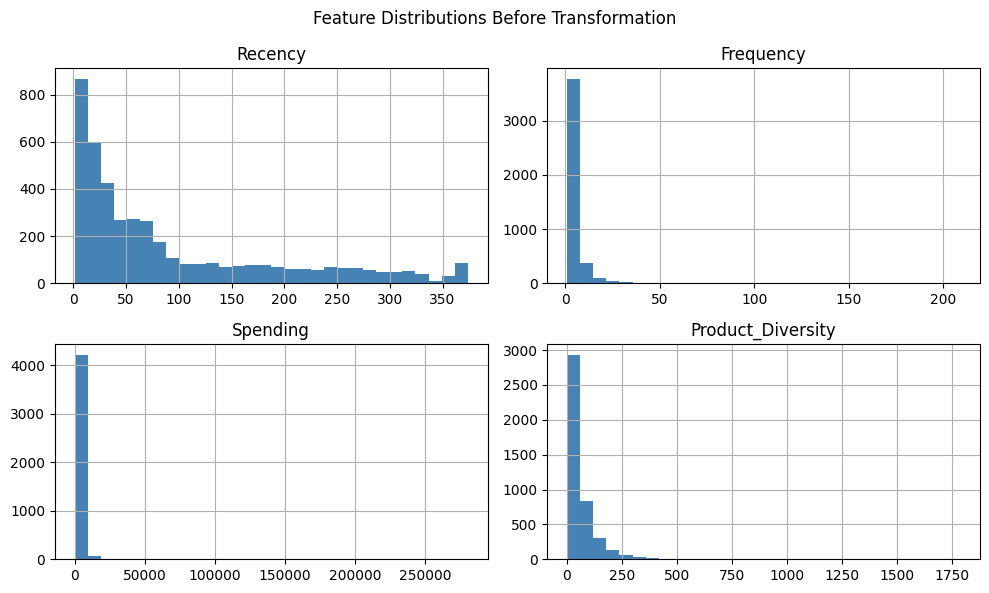

In [4]:
features = ['Recency', 'Frequency', 'Spending', 'Product_Diversity']
print('Skewness before transformation:')
print(customer_df[features].skew())

customer_df[features].hist(bins=30, figsize=(10, 6), color='steelblue')
plt.suptitle('Feature Distributions Before Transformation')
plt.tight_layout()
plt.savefig('figures/features_before_transform.png')
plt.show()

## 5. Log Transformation (Handling Skewness & Outliers)

All metrics (especially `Spending` with skewness 19.33 and `Frequency` with skewness 12.07) are severely right-skewed.
We apply `np.log1p` ($f(x) = \ln(1+x)$) to normalize distributions, stabilize variance, and compress extreme values while preserving relative order.

Skewness after Log Transformation:
Recency             -0.379169
Frequency            1.208652
Spending             0.396599
Product_Diversity   -0.243262
dtype: float64


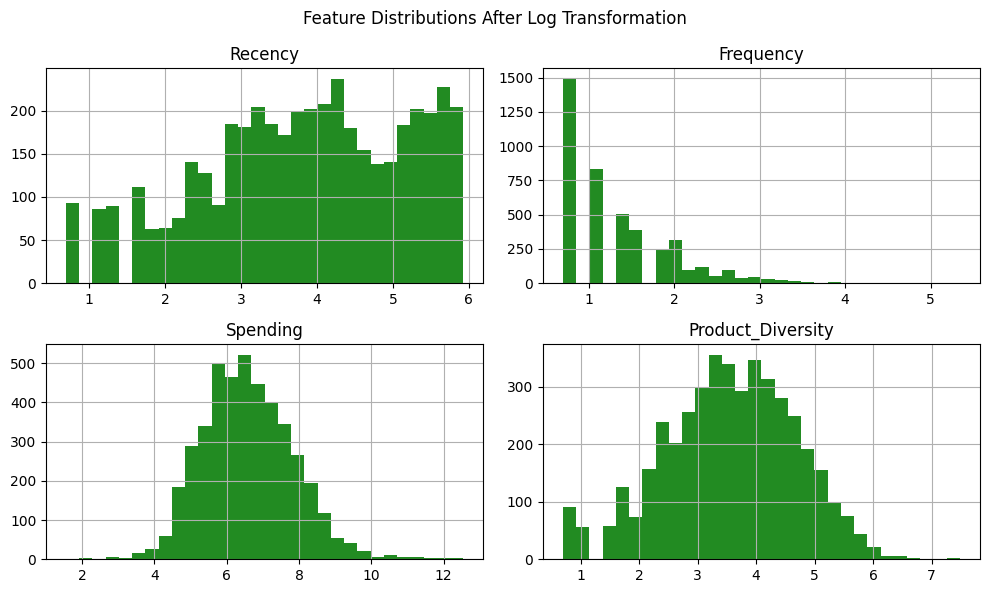

In [5]:
customer_log = customer_df[features].apply(np.log1p)

print('Skewness after Log Transformation:')
print(customer_log.skew())

customer_log.hist(bins=30, figsize=(10, 6), color='forestgreen')
plt.suptitle('Feature Distributions After Log Transformation')
plt.tight_layout()
plt.savefig('figures/features_after_log_transform.png')
plt.show()

## 6. Numerical Feature Standardization (Scaling)

Because features have vastly different units (days vs. order counts vs. monetary amounts), we apply `StandardScaler` to ensure all features contribute equally to Euclidean distance calculations with a mean of 0 and unit variance (std = 1).

In [6]:
scaler = StandardScaler()
scaled_features = scaler.fit_transform(customer_log)

scaled_df = pd.DataFrame(
    scaled_features,
    columns=[
        'Recency_scaled',
        'Frequency_scaled',
        'Spending_scaled',
        'Diversity_scaled',
    ],
)
scaled_df['CustomerID'] = customer_df['CustomerID']

print(scaled_df.head())
print('\nMeans:\n', scaled_df.iloc[:, :4].mean().round(2))
print('Standard Deviations:\n', scaled_df.iloc[:, :4].std().round(2))

   Recency_scaled  Frequency_scaled  Spending_scaled  Diversity_scaled  \
0        1.461993         -0.955214         3.707716         -2.526376   
1       -2.038734          1.074425         1.414903          0.965881   
2        0.373104          0.386304         0.720024         -0.367738   
3       -0.623086         -0.955214         0.702287          0.665088   
4        1.424558         -0.955214        -0.614514         -0.584387   

   CustomerID  
0       12346  
1       12347  
2       12348  
3       12349  
4       12350  

Means:
 Recency_scaled     -0.0
Frequency_scaled   -0.0
Spending_scaled    -0.0
Diversity_scaled    0.0
dtype: float64
Standard Deviations:
 Recency_scaled      1.0
Frequency_scaled    1.0
Spending_scaled     1.0
Diversity_scaled    1.0
dtype: float64


## 7. Reusable Feature Engineering Pipeline

As specified in the DEPI project deliverables, we encapsulate the entire transformation workflow (aggregation, log transformation, and standardization) into a reusable pipeline function.
This function enables automated preprocessing for new transactional batches or model retraining.

In [ ]:
def feature_engineering_pipeline(cleaned_df):

    snapshot_date = cleaned_df['InvoiceDate'].max() + pd.Timedelta(days=1)

    cust = (
        cleaned_df.groupby('CustomerID')
        .agg(
            Recency=('InvoiceDate', lambda x: (snapshot_date - x.max()).days),
            Frequency=('InvoiceNo', 'nunique'),
            Spending=('TotalPrice', 'sum'),
            Product_Diversity=('StockCode', 'nunique'),
        )
        .reset_index()
    )

    feature_cols = ['Recency', 'Frequency', 'Spending', 'Product_Diversity']

    log_transformed = cust[feature_cols].apply(np.log1p)

    scaler = StandardScaler()
    scaled_vals = scaler.fit_transform(log_transformed)

    final_features_df = cust.copy()
    for i, col in enumerate([
        'Recency_scaled',
        'Frequency_scaled',
        'Spending_scaled',
        'Diversity_scaled',
    ]):
        final_features_df[col] = scaled_vals[:, i]

    return final_features_df, scaler


final_customer_df, fitted_scaler = feature_engineering_pipeline(df)
print('Pipeline executed successfully! Final shape:', final_customer_df.shape)

## 8. Export Processed Features for Modeling Phase

We export the final feature dataset (`customer_features.csv`) so that Member 3 (Clustering & MLflow Lead) can directly load and train K-Means and DBSCAN models in `03_customer_segmentation.ipynb`.

In [8]:
final_customer_df.to_csv('customer_features.csv', index=False)
print('Saved customer_features.csv successfully for Modeling phase!')

Saved customer_features.csv successfully for Modeling phase!


## 9. Feature Engineering Findings & Next Steps

**Behavioral Features Created**
- Extracted 4 core behavioral features for 4,338 unique customers:
  - `Recency`: Range 1 to 374 days (median ~50 days).
  - `Frequency`: Range 1 to 210 distinct orders (median 2 orders).
  - `Spending`: Range £3.75 to £280,206 (median £669, mean £2,049).
  - `Product_Diversity`: Range 1 to 1,794 distinct products (median 35 products).

**Transformation Results**
- The raw metrics suffered from extreme right-skewness (Spending: 19.33, Frequency: 12.07).
- Applying `np.log1p` successfully stabilized variance and shifted features toward normal distributions:
  - Spending skewness dropped from 19.33 to **0.39** (near perfect symmetry).
  - Product diversity skewness dropped from 6.94 to **0.38**.
  - Frequency skewness dropped from 12.07 to **1.21**.
  - Recency skewness shifted from 1.25 to **-0.38**.

**Standardization & Handoff**
- Scaled features have mean $0.0$ and std $1.0$, preventing higher-magnitude variables (like spending) from dominating distance calculations.
- `customer_features.csv` is now ready for **Notebook 03 (Customer Segmentation & MLflow Tracking)**.